# Telco Customer Churn: Random Forest vs XGBoost

**Goal:** Predict which telecom customers will churn, handle the class imbalance, and reach a **ROC-AUC above 0.80**.

**Pipeline**
1. Load data; convert `TotalCharges` to numeric and handle nulls
2. Exploratory analysis of churn drivers
3. Stratified 80/20 split
4. `OneHotEncoder` for categorical features
5. Class imbalance: **class weighting** and **SMOTE**, compared side by side
6. Train Random Forest and XGBoost with 5-fold cross-validation
7. ROC curves, confusion matrices, top-10 feature importances

## 1. Imports and setup

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, roc_curve, average_precision_score,
                             accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
%matplotlib inline

## 2. Load the data and clean `TotalCharges`

In [28]:
try:
    df = pd.read_csv("telco_customer_churn.csv")   # keep the CSV in the same folder as this notebook
except FileNotFoundError:
    df = pd.read_csv("https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv")

print("Shape:", df.shape)
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [29]:
print(df.dtypes)
print("\nTotalCharges dtype is object because some cells are blank strings.")
blank = df["TotalCharges"].str.strip() == ""
print("Blank TotalCharges rows:", blank.sum())
df.loc[blank, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

TotalCharges dtype is object because some cells are blank strings.
Blank TotalCharges rows: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


All blank `TotalCharges` rows have `tenure = 0`: these customers signed up but have not been billed yet. Their total charges are genuinely **0**, so filling with 0 is more accurate than a median. The rule is deterministic (it does not use other rows), so applying it before the split causes no leakage.

In [30]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Nulls after conversion:", df["TotalCharges"].isna().sum())
df["TotalCharges"] = df["TotalCharges"].fillna(0)

df = df.drop(columns="customerID")                       # identifier, no predictive value
df["Churn"] = (df["Churn"] == "Yes").astype(int)         # target: 1 = churned
print("Remaining nulls:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum(), "(kept: after dropping the ID these are plausibly different customers on identical plans)")

Nulls after conversion: 11
Remaining nulls: 0
Duplicate rows: 22 (kept: after dropping the ID these are plausibly different customers on identical plans)


## 3. Exploratory analysis and class imbalance

Stayed: 5174  |  Churned: 1869  |  churn rate = 26.5%


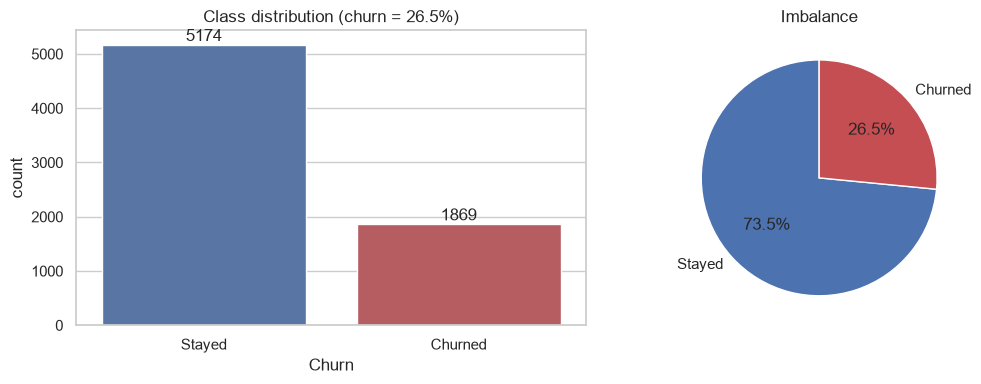

In [31]:
counts = df["Churn"].value_counts()
rate = df["Churn"].mean()
print(f"Stayed: {counts[0]}  |  Churned: {counts[1]}  |  churn rate = {rate:.1%}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x="Churn", data=df, ax=axes[0], palette=["#4c72b0", "#c44e52"], hue="Churn", legend=False)
axes[0].set_xticks([0, 1]); axes[0].set_xticklabels(["Stayed", "Churned"])
axes[0].set_title(f"Class distribution (churn = {rate:.1%})")
for p in axes[0].patches:
    axes[0].annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                     ha="center", va="bottom")
axes[1].pie(counts, labels=["Stayed", "Churned"], autopct="%1.1f%%", colors=["#4c72b0", "#c44e52"], startangle=90)
axes[1].set_title("Imbalance")
plt.tight_layout(); plt.show()

**The data is imbalanced:** roughly 3 in 4 customers stay. A model that always predicts "stayed" would score about 73% accuracy while catching zero churners, so **accuracy is misleading here**. That is why the task asks for ROC-AUC, and why recall on the churn class is tracked as well.

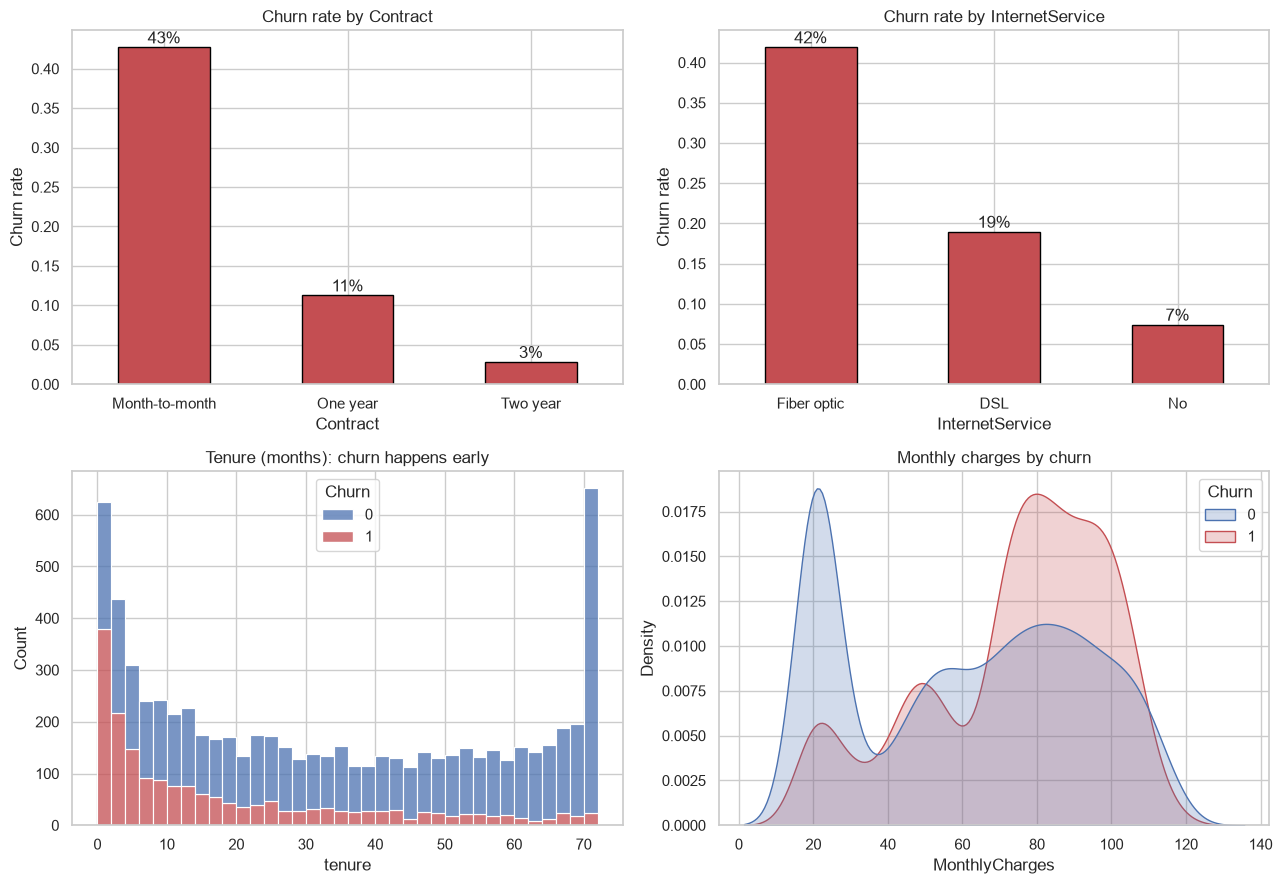

In [32]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, col in zip(axes.ravel()[:2], ["Contract", "InternetService"]):
    rates = df.groupby(col)["Churn"].mean().sort_values(ascending=False)
    rates.plot(kind="bar", ax=ax, color="#c44e52", edgecolor="black")
    ax.set_title(f"Churn rate by {col}"); ax.set_ylabel("Churn rate"); ax.tick_params(axis="x", rotation=0)
    for i, v in enumerate(rates):
        ax.text(i, v + 0.005, f"{v:.0%}", ha="center")

sns.histplot(data=df, x="tenure", hue="Churn", multiple="stack", bins=36, ax=axes[1, 0],
             palette=["#4c72b0", "#c44e52"])
axes[1, 0].set_title("Tenure (months): churn happens early")

sns.kdeplot(data=df, x="MonthlyCharges", hue="Churn", fill=True, common_norm=False, ax=axes[1, 1],
            palette=["#4c72b0", "#c44e52"])
axes[1, 1].set_title("Monthly charges by churn")
plt.tight_layout(); plt.show()

**Observations**
- **Month-to-month** contracts churn far more than one- or two-year contracts.
- **Fibre optic** customers churn more than DSL or no-internet customers.
- Churn is concentrated in the **first months** of tenure.
- Churners tend to pay **higher monthly charges**.

## 4. Train/test split and preprocessing

The split is stratified, so both parts keep the same ~26.5% churn rate. Categorical columns are encoded with `OneHotEncoder` inside the pipeline (fitted on training data only). Tree-based models do not need feature scaling.

In [33]:
X = df.drop(columns="Churn")
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)
print(f"Train: {len(X_train)} rows (churn {y_train.mean():.1%}) | Test: {len(X_test)} rows (churn {y_test.mean():.1%})")

cat_features = X.select_dtypes(exclude="number").columns.tolist()
num_features = [c for c in X.columns if c not in cat_features]
print("\nCategorical:", len(cat_features), "| Numeric:", num_features)

def make_prep():
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_features),
        ("num", "passthrough", num_features),
    ])

Train: 5634 rows (churn 26.5%) | Test: 1409 rows (churn 26.5%)

Categorical: 15 | Numeric: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


## 5. Handling class imbalance and defining the models

Two standard approaches are compared for each algorithm:

| Approach | How it works |
|---|---|
| **Class weighting** | Errors on the minority (churn) class cost more. `class_weight="balanced_subsample"` for Random Forest, `scale_pos_weight` for XGBoost |
| **SMOTE** | Creates synthetic minority-class samples. It runs **inside** the pipeline, so during cross-validation only the training folds are oversampled and validation folds stay untouched |

`scale_pos_weight` is the ratio of negative to positive training samples.

In [34]:
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
spw = neg / pos
print(f"scale_pos_weight = {neg}/{pos} = {spw:.2f}")

def rf(**kw):
    return RandomForestClassifier(n_estimators=300, max_depth=10, min_samples_leaf=5,
                                  random_state=RANDOM_STATE, n_jobs=-1, **kw)

def xgb(**kw):
    return XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8,
                         colsample_bytree=0.8, eval_metric="logloss",
                         random_state=RANDOM_STATE, n_jobs=-1, **kw)

models = {
    "RF + class weight":  ImbPipeline([("prep", make_prep()), ("model", rf(class_weight="balanced_subsample"))]),
    "RF + SMOTE":         ImbPipeline([("prep", make_prep()), ("smote", SMOTE(random_state=RANDOM_STATE)), ("model", rf())]),
    "XGB + scale_pos_weight": ImbPipeline([("prep", make_prep()), ("model", xgb(scale_pos_weight=spw))]),
    "XGB + SMOTE":        ImbPipeline([("prep", make_prep()), ("smote", SMOTE(random_state=RANDOM_STATE)), ("model", xgb())]),
}
print("Models defined:", list(models))

scale_pos_weight = 4139/1495 = 2.77
Models defined: ['RF + class weight', 'RF + SMOTE', 'XGB + scale_pos_weight', 'XGB + SMOTE']


## 6. Cross-validation (5-fold, stratified, on the training set)

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, pipe in models.items():
    res = cross_validate(pipe, X_train, y_train, cv=cv, n_jobs=1,
                         scoring={"roc_auc": "roc_auc", "recall": "recall", "f1": "f1"})
    cv_rows.append({"Model": name,
                    "CV ROC-AUC": res["test_roc_auc"].mean(), "± std": res["test_roc_auc"].std(),
                    "CV Recall": res["test_recall"].mean(), "CV F1": res["test_f1"].mean()})
cv_results = pd.DataFrame(cv_rows).set_index("Model").round(4)
cv_results

## 7. Final fit and test-set evaluation

In [ ]:
fitted, proba, pred = {}, {}, {}
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    proba[name] = pipe.predict_proba(X_test)[:, 1]
    pred[name] = pipe.predict(X_test)

rows = []
for name in models:
    rows.append({"Model": name,
                 "ROC-AUC": roc_auc_score(y_test, proba[name]),
                 "PR-AUC": average_precision_score(y_test, proba[name]),
                 "Accuracy": accuracy_score(y_test, pred[name]),
                 "Precision": precision_score(y_test, pred[name]),
                 "Recall": recall_score(y_test, pred[name]),
                 "F1": f1_score(y_test, pred[name])})
results = pd.DataFrame(rows).set_index("Model").round(4)
best = results["ROC-AUC"].idxmax()
print(f"Best model by test ROC-AUC: {best}  ({results.loc[best, 'ROC-AUC']:.4f})")
print("Target ROC-AUC > 0.80 met by all models:", bool((results['ROC-AUC'] > 0.80).all()))
results

Best model by test ROC-AUC: XGB + SMOTE  (0.8471)
Target ROC-AUC > 0.80 met by all models: True


,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1
Model,,,,,,
RF + class weight,0.8421,0.6539,0.7700,0.5481,0.7620,0.6376
RF + SMOTE,0.8360,0.6305,0.7771,0.5754,0.6123,0.5933
XGB + scale_pos_weight,0.8438,0.6625,0.7480,0.5167,0.7861,0.6235
XGB + SMOTE,0.8471,0.6690,0.7991,0.6334,0.5775,0.6042


Precision, recall and F1 above use the default **0.5 probability threshold**, and refer to the churn class. ROC-AUC and PR-AUC are threshold-independent.

## 8. ROC curves

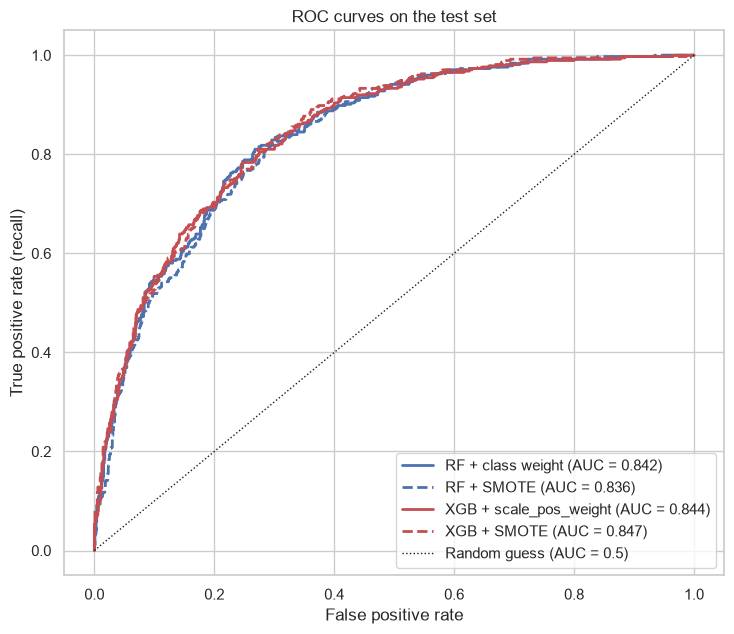

In [ ]:
fig, ax = plt.subplots(figsize=(7.5, 6.5))
styles = {"RF + class weight": ("#4c72b0", "-"), "RF + SMOTE": ("#4c72b0", "--"),
          "XGB + scale_pos_weight": ("#c44e52", "-"), "XGB + SMOTE": ("#c44e52", "--")}
for name in models:
    fpr, tpr, _ = roc_curve(y_test, proba[name])
    col, ls = styles[name]
    ax.plot(fpr, tpr, color=col, ls=ls, lw=2, label=f"{name} (AUC = {results.loc[name, 'ROC-AUC']:.3f})")
ax.plot([0, 1], [0, 1], "k:", lw=1, label="Random guess (AUC = 0.5)")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate (recall)")
ax.set_title("ROC curves on the test set"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

## 9. Confusion matrices

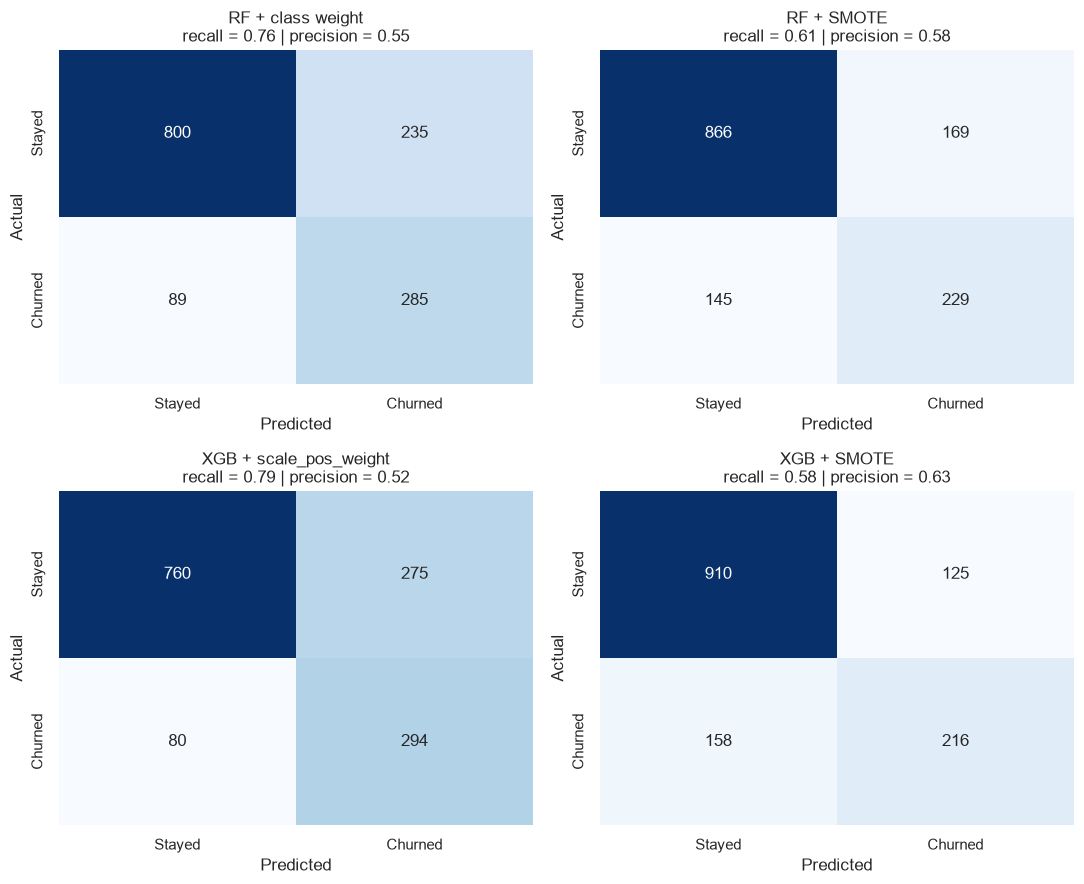

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, name in zip(axes.ravel(), models):
    cm = confusion_matrix(y_test, pred[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Stayed", "Churned"], yticklabels=["Stayed", "Churned"])
    ax.set_title(f"{name}\nrecall = {recall_score(y_test, pred[name]):.2f} | precision = {precision_score(y_test, pred[name]):.2f}")
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

Reading a matrix: the bottom-left cell holds **churners the model missed** (false negatives) and the top-right holds **loyal customers wrongly flagged** (false positives). Class weighting and SMOTE both push the model to catch more churners, at the cost of more false alarms.

## 10. Top 10 most influential features

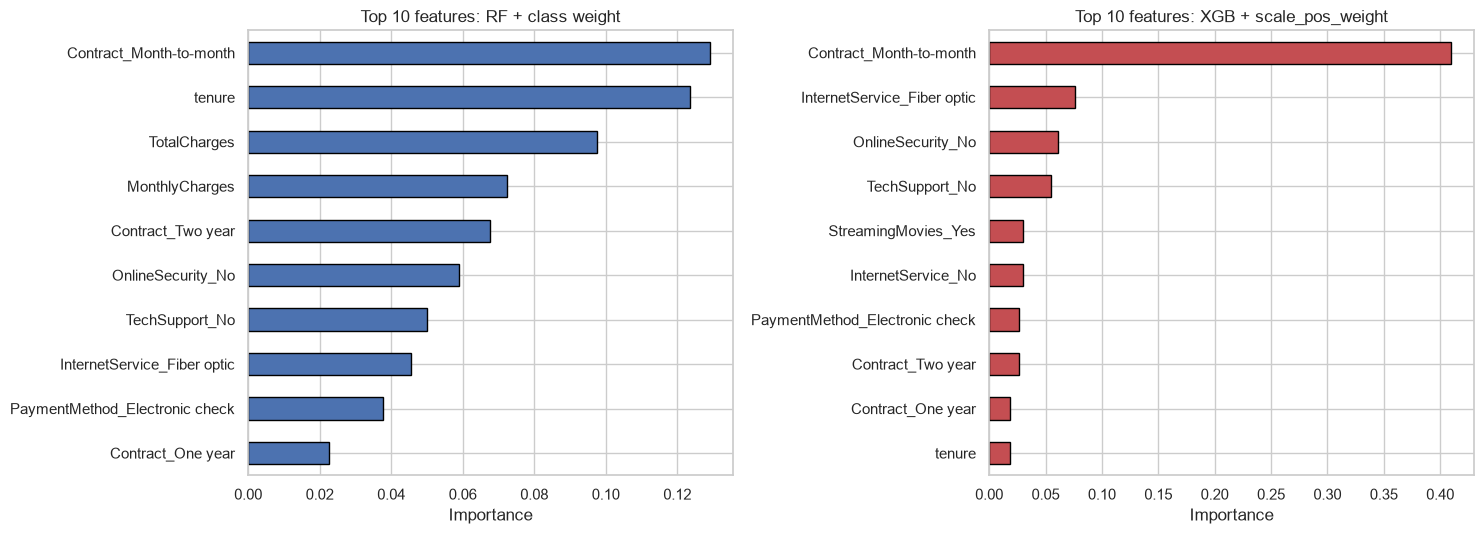

Random Forest top 10:
Contract_Month-to-month           0.1291
tenure                            0.1234
TotalCharges                      0.0975
MonthlyCharges                    0.0723
Contract_Two year                 0.0677
OnlineSecurity_No                 0.0590
TechSupport_No                    0.0500
InternetService_Fiber optic       0.0456
PaymentMethod_Electronic check    0.0376
Contract_One year                 0.0227

XGBoost top 10:
Contract_Month-to-month           0.4095
InternetService_Fiber optic       0.0761
OnlineSecurity_No                 0.0609
TechSupport_No                    0.0550
StreamingMovies_Yes               0.0301
InternetService_No                0.0299
PaymentMethod_Electronic check    0.0263
Contract_Two year                 0.0261
Contract_One year                 0.0184
tenure                            0.0183


In [ ]:
def top_features(pipe, n=10):
    names = pipe.named_steps["prep"].get_feature_names_out()
    names = [x.split("__", 1)[1] for x in names]
    imp = pd.Series(pipe.named_steps["model"].feature_importances_, index=names)
    return imp.sort_values(ascending=False).head(n)[::-1]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, name, col in [(axes[0], "RF + class weight", "#4c72b0"), (axes[1], "XGB + scale_pos_weight", "#c44e52")]:
    imp = top_features(fitted[name])
    imp.plot(kind="barh", ax=ax, color=col, edgecolor="black")
    ax.set_title(f"Top 10 features: {name}"); ax.set_xlabel("Importance")
plt.tight_layout(); plt.show()

print("Random Forest top 10:"); print(top_features(fitted["RF + class weight"])[::-1].round(4).to_string())
print("\nXGBoost top 10:"); print(top_features(fitted["XGB + scale_pos_weight"])[::-1].round(4).to_string())

**Note:** feature importance shows *which* features the model relies on, not the *direction* of the effect. The EDA in section 3 gives that direction: short tenure, month-to-month contracts, fibre optic internet and higher monthly charges go with higher churn.

## 11. Conclusion

- **Target met:** all four models exceed the required ROC-AUC of 0.80, with cross-validated scores of about 0.84 to 0.85 and test scores of 0.837 to 0.846. The gaps between models are smaller than the cross-validation spread (about 0.01), so **no algorithm is clearly better on ROC-AUC**.
- **The imbalance method changes the trade-off more than the algorithm does.** Class weighting finds far more churners (recall 0.76 for Random Forest, 0.79 for XGBoost) than SMOTE (0.57 to 0.61), at the cost of more false alarms (precision 0.52 to 0.55 versus 0.57 to 0.63). The SMOTE models show higher accuracy (up to 0.80), but that is the misleading metric on a 73/27 split.
- **Recommended model:** XGBoost with `scale_pos_weight`. It has the highest recall (0.79) and one of the two best PR-AUC scores (0.667) while matching the top ROC-AUC. If false alarms are expensive for the business, the SMOTE variants or a higher decision threshold are the alternative.
- **Main churn drivers** (both models agree): a month-to-month contract is the dominant signal, followed by short tenure, no online security, no tech support, fibre optic internet and paying by electronic check.
- **Limitations:** results come from one train/test split on 1,409 test customers, so small differences are noise. SMOTE was applied after one-hot encoding, so synthetic samples contain fractional category values (SMOTENC would handle this more rigorously). The 0.5 threshold was not tuned, and a lower threshold would raise recall further. No hyperparameter search was run, so a tuned model might improve on these scores.